# GulfMetric: Geometric Scale Correction for MoGe-2 on KITTI

**Pipeline:** frozen MoGe-2 → 3D points (metres) → fit the road plane → `s = 1.65 / h_pred` → rescale → compare with LiDAR.

**Before running:** Runtime → Change runtime type → **T4 GPU**. Then run the cells in order.

| Variant | Focal length | Scale correction |
|---|---|---|
| (a) baseline | MoGe-2 guesses | none |
| (b) + true focal | from KITTI intrinsics | none |
| (c) + GSC | MoGe-2 guesses | ground plane + camera height |
| (d) full | from KITTI intrinsics | ground plane + camera height |
| (d') full, least squares | from KITTI intrinsics | plane by plain least squares (no RANSAC) |
| oracle | MoGe-2 guesses | median scaling with ground truth (upper bound, cheats) |

Data: KITTI depth "selected validation" set (1000 images, 1216×352, LiDAR ground truth). Fixed split: first 100 names (sorted) = dev, used only to choose the RANSAC threshold; remaining 900 = test.

In [1]:
# 1. Setup: GPU check, Google Drive, MoGe install
import shutil, subprocess
assert shutil.which("nvidia-smi"), "No GPU! Runtime > Change runtime type > T4 GPU, then run this cell again."
GPU_NAME = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                          capture_output=True, text=True).stdout.strip()
print("GPU:", GPU_NAME)

from google.colab import drive
drive.mount('/content/drive')

!pip -q install git+https://github.com/microsoft/MoGe.git

GPU: Tesla T4, 15360 MiB
Mounted at /content/drive
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
# 2. Paths, settings and data loaders
import os, time, math, json
import numpy as np, cv2, torch, pandas as pd
import matplotlib.pyplot as plt

ROOT  = "/content/drive/MyDrive/GulfMetric"
KITTI = f"{ROOT}/kitti/val_selection_cropped"
RES   = f"{ROOT}/results"
FIG   = f"{RES}/figures"
os.makedirs(FIG, exist_ok=True)

CKPT      = "Ruicheng/moge-2-vitl"   # MoGe-2 ViT-L, metric scale
H_TRUE    = 1.65                     # KITTI camera height above the road (m)
MAX_DEPTH = 80.0                     # standard KITTI evaluation cap (m)
MIN_DEPTH = 1e-3

dev_names  = open(f"{ROOT}/splits/dev.txt").read().split()
test_names = open(f"{ROOT}/splits/test.txt").read().split()
print(len(dev_names), "dev /", len(test_names), "test images")

def gt_name(n):            # only the FIRST "_image_" is replaced
    return n.replace("_image_", "_groundtruth_depth_", 1)

def load_rgb(n):
    return cv2.cvtColor(cv2.imread(f"{KITTI}/image/{n}.png"), cv2.COLOR_BGR2RGB)

def load_gt(n):            # 16-bit PNG, metres = value / 256, 0 = no LiDAR point
    g = cv2.imread(f"{KITTI}/groundtruth_depth/{gt_name(n)}.png", cv2.IMREAD_UNCHANGED)
    return g.astype(np.float32) / 256.0

def load_K(n):             # 3x3 camera matrix stored as 9 numbers
    return np.loadtxt(f"{KITTI}/intrinsics/{n}.txt").reshape(3, 3)

def fov_x_deg(K, width):
    return math.degrees(2 * math.atan(width / (2 * K[0, 0])))

n0 = dev_names[0]
print(load_rgb(n0).shape, "GT valid pixels:", int((load_gt(n0) > 0).sum()),
      "fov_x =", round(fov_x_deg(load_K(n0), 1216), 1), "deg")

100 dev / 900 test images
(352, 1216, 3) GT valid pixels: 99247 fov_x = 80.2 deg


In [3]:
# 3. Load the frozen MoGe-2 model (inference only, no training)
from moge.model.v2 import MoGeModel
device = torch.device("cuda")
model = MoGeModel.from_pretrained(CKPT).to(device).eval()

def run_moge(rgb, fov_x=None):
    '''rgb: HxWx3 uint8. Returns points (HxWx3, metres, OpenCV camera coords), valid mask, runtime in ms.'''
    x = torch.tensor(rgb / 255.0, dtype=torch.float32, device=device).permute(2, 0, 1)
    torch.cuda.synchronize(); t = time.perf_counter()
    with torch.no_grad():
        out = model.infer(x, fov_x=fov_x)
    torch.cuda.synchronize(); ms = (time.perf_counter() - t) * 1000
    pts = out["points"].float().cpu().numpy()
    mask = out["mask"].cpu().numpy().astype(bool) if "mask" in out else np.ones(pts.shape[:2], bool)
    mask &= np.isfinite(pts).all(-1) & (pts[..., 2] > 0)
    pts[~mask] = 0
    return pts, mask, ms

# warm-up (first call is always slow), then reset the memory counter
_rgb = load_rgb(n0)
run_moge(_rgb); run_moge(_rgb, fov_x=fov_x_deg(load_K(n0), _rgb.shape[1]))
torch.cuda.reset_peak_memory_stats()
print("MoGe-2 ready")

model.pt: reconstructing file:   0%|          |  0.00B / 1.31GB            

model.pt: downloading bytes:           |  0.00B            

MoGe-2 ready


In [4]:
# 4. Geometric Scale Correction (GSC): our contribution
def fit_plane_svd(P):
    '''Least-squares plane through points P (Nx3). Returns unit normal n and offset d (n.p + d = 0).'''
    c = P.mean(0)
    _, _, vt = np.linalg.svd(P - c, full_matrices=False)
    n = vt[-1]
    return n, -n @ c

def ransac_plane(P, thresh, iters=300, rng=None):
    '''RANSAC over roughly horizontal planes. Returns the inlier mask of the best plane (or None).'''
    rng = rng if rng is not None else np.random.default_rng(0)
    idx = rng.integers(0, len(P), size=(iters, 3))
    A, B, C = P[idx[:, 0]], P[idx[:, 1]], P[idx[:, 2]]
    N = np.cross(B - A, C - A)
    norm = np.linalg.norm(N, axis=1)
    keep = norm > 1e-9
    N, A = N[keep] / norm[keep, None], A[keep]
    horiz = np.abs(N[:, 1]) > 0.8          # y axis points down: ground normal is close to +-y
    N, A = N[horiz], A[horiz]
    if len(N) == 0:
        return None
    D = -(N * A).sum(1)
    dist = np.abs(P @ N.T + D)             # (num_points, num_planes)
    best = (dist < thresh).sum(0).argmax()
    return dist[:, best] < thresh

def gsc(points, mask, h_true=H_TRUE, thresh=0.10, method="ransac",
        min_inliers=500, max_pts=20000, seed=0):
    '''Scale a predicted point map so the camera sits h_true metres above the fitted ground plane.'''
    t = time.perf_counter()
    H = points.shape[0]
    cand = mask.copy()
    cand[: int(H * 2 / 3)] = False         # ground candidates: bottom third of the image
    P = points[cand]
    rng = np.random.default_rng(seed)
    if len(P) > max_pts:
        P = P[rng.choice(len(P), max_pts, replace=False)]
    info = {"n_ground": int(cand.sum()), "n_inliers": 0, "fallback": False}
    n = d = None
    if len(P) >= min_inliers:
        if method == "ransac":
            inl = ransac_plane(P, thresh, rng=rng)
            if inl is not None and inl.sum() >= min_inliers:
                n, d = fit_plane_svd(P[inl]); info["n_inliers"] = int(inl.sum())
        else:                               # ablation: plain least squares on all candidates
            n, d = fit_plane_svd(P); info["n_inliers"] = len(P)
    if n is not None and abs(n[1]) > 0.8 and abs(d) > 1e-6:
        h_pred = abs(d)                     # camera-to-plane distance (n is unit length)
        s = h_true / h_pred
    else:                                   # no reliable ground: leave the prediction unchanged
        h_pred, s = np.nan, 1.0
        info["fallback"] = True
    info.update(h_pred=h_pred, s=s, gsc_ms=(time.perf_counter() - t) * 1000)
    return points * s, s, info

In [5]:
# 5. Metrics (standard KITTI depth metrics on pixels with LiDAR ground truth, capped at 80 m)
def depth_metrics(pred, gt, valid):
    p = np.clip(pred[valid], MIN_DEPTH, MAX_DEPTH); g = gt[valid]
    absrel = np.mean(np.abs(p - g) / g)
    rmse   = np.sqrt(np.mean((p - g) ** 2))
    d1     = np.mean(np.maximum(p / g, g / p) < 1.25)
    return absrel, rmse, d1

def absrel_bins(pred, gt, valid, bins=((0, 20), (20, 40), (40, 80))):
    out = {}
    for lo, hi in bins:
        v = valid & (gt > lo) & (gt <= hi)
        out[f"{lo}_{hi}m"] = (np.mean(np.abs(np.clip(pred[v], MIN_DEPTH, MAX_DEPTH) - gt[v]) / gt[v])
                              if v.sum() > 0 else np.nan)
    return out

In [ ]:
# 6. Choose the RANSAC threshold on DEV images only (never on test)
dev_cache = []
for i, n in enumerate(dev_names):
    rgb, gt, K = load_rgb(n), load_gt(n), load_K(n)
    pk, mk, _ = run_moge(rgb, fov_x=fov_x_deg(K, rgb.shape[1]))
    dev_cache.append((gt, pk.astype(np.float16), mk))
    if i % 25 == 0: print("dev", i)

THRESHOLDS = [0.03, 0.05, 0.10, 0.20, 0.30]   # metres, in the model's (unscaled) units
rows = []
for th in THRESHOLDS:
    errs, fb = [], 0
    for gt, pk, mk in dev_cache:
        ps, _, info = gsc(pk.astype(np.float32), mk, thresh=th)
        v = (gt > 0) & (gt <= MAX_DEPTH) & mk
        errs.append(depth_metrics(ps[..., 2], gt, v)[0]); fb += info["fallback"]
    rows.append({"ransac_thresh_m": th, "dev_AbsRel_variant_d": np.mean(errs), "dev_fallbacks": fb})
dev_df = pd.DataFrame(rows)
BEST_TH = float(dev_df.loc[dev_df.dev_AbsRel_variant_d.idxmin(), "ransac_thresh_m"])
dev_df.to_csv(f"{RES}/dev_threshold_sweep.csv", index=False)
json.dump({"ckpt": CKPT, "ransac_thresh_m": BEST_TH, "h_true": H_TRUE, "gpu": GPU_NAME},
          open(f"{RES}/config.json", "w"), indent=2)
del dev_cache
display(dev_df); print("Chosen RANSAC threshold:", BEST_TH, "m")

dev 0
dev 25
dev 50
dev 75


,ransac_thresh_m,dev_AbsRel_variant_d,dev_fallbacks
0,0.03,0.109877,0
1,0.05,0.105144,0
2,0.10,0.100791,0
3,0.20,0.100041,0
4,0.30,0.144436,0


Chosen RANSAC threshold: 0.2 m


In [ ]:
# 7. Main experiment on the 900 TEST images (resume-safe: re-run this cell after a disconnect)
OUT = f"{RES}/per_image_test.csv"
BEST_TH = json.load(open(f"{RES}/config.json"))["ransac_thresh_m"]
done = set(pd.read_csv(OUT)["name"]) if os.path.exists(OUT) else set()
todo = [n for n in test_names if n not in done]
print(len(done), "done,", len(todo), "to go")

for i, n in enumerate(todo):
    rgb, gt, K = load_rgb(n), load_gt(n), load_K(n)
    pa, ma, ms_a = run_moge(rgb)                                         # model guesses focal length
    pk, mk, ms_k = run_moge(rgb, fov_x=fov_x_deg(K, rgb.shape[1]))       # true focal length
    p_c, s_c, i_c = gsc(pa, ma, thresh=BEST_TH)
    p_d, s_d, i_d = gsc(pk, mk, thresh=BEST_TH)
    p_l, s_l, i_l = gsc(pk, mk, method="lstsq")
    base = (gt > 0) & (gt <= MAX_DEPTH)
    va, vk = base & ma, base & mk
    if va.sum() < 10 or vk.sum() < 10:
        continue
    r = {"name": n}
    for key, (pred, v) in {"a_baseline": (pa[..., 2], va), "b_true_focal": (pk[..., 2], vk),
                           "c_gsc": (p_c[..., 2], va), "d_full": (p_d[..., 2], vk),
                           "d_lstsq": (p_l[..., 2], vk)}.items():
        r[f"{key}_AbsRel"], r[f"{key}_RMSE"], r[f"{key}_d1"] = depth_metrics(pred, gt, v)
    s_or = np.median(gt[va]) / np.median(pa[..., 2][va])                 # oracle: uses ground truth
    r["oracle_AbsRel"], r["oracle_RMSE"], r["oracle_d1"] = depth_metrics(pa[..., 2] * s_or, gt, va)
    for k, v in absrel_bins(pa[..., 2], gt, va).items(): r[f"a_AbsRel_{k}"] = v
    for k, v in absrel_bins(p_d[..., 2], gt, vk).items(): r[f"d_AbsRel_{k}"] = v
    r.update(ms_auto=ms_a, ms_true_focal=ms_k, gsc_ms=i_d["gsc_ms"], s_c=s_c, s_d=s_d, s_oracle=s_or,
             h_pred_d=i_d["h_pred"], inliers_d=i_d["n_inliers"],
             fallback_c=i_c["fallback"], fallback_d=i_d["fallback"])
    pd.DataFrame([r]).to_csv(OUT, mode="a", header=not os.path.exists(OUT), index=False)
    if i % 50 == 0:
        print(f"{i}/{len(todo)}  a={r['a_baseline_AbsRel']:.3f}  d={r['d_full_AbsRel']:.3f}  s={s_d:.3f}")

peak = torch.cuda.max_memory_allocated() / 1e9
json.dump({**json.load(open(f"{RES}/config.json")), "peak_gpu_mem_GB": round(peak, 2)},
          open(f"{RES}/config.json", "w"), indent=2)
print("Finished. Peak GPU memory:", round(peak, 2), "GB")

900 done, 0 to go
Finished. Peak GPU memory: 2.38 GB


,variant,AbsRel,RMSE (m),delta<1.25 (%),AbsRel change vs (a) (%)
0,(a) baseline MoGe-2,0.2219,4.6164,39.6005,0.0000
1,(b) + true focal length,0.1332,3.8638,86.0391,-39.9934
2,(c) + GSC,0.1192,3.2377,92.3776,-46.2781
3,(d) true focal + GSC (ours),0.1481,4.2426,82.1403,-33.2779
4,"(d') full, least-squares plane",0.4130,7.7033,51.0494,86.0913
5,oracle median scaling (uses GT),0.0549,2.5776,97.3756,-75.2689


,GT distance,(a) AbsRel,(d) AbsRel
0,0_20m,0.2249,0.1392
1,20_40m,0.2011,0.1703
2,40_80m,0.2316,0.2061


,test images,GPU,MoGe-2 ms/img (auto focal),MoGe-2 ms/img (true focal),GSC ms/img,peak GPU memory (GB),GSC fallback (%),mean scale s (d),mean oracle scale
0,900,"Tesla T4, 15360 MiB",441.98,379.416,36.326,2.38,0.0,1.093,1.291


Hypothesis (>=30% lower AbsRel, <30 ms extra): AbsRel change 33.3% lower, GSC 36.3 ms -> NOT supported


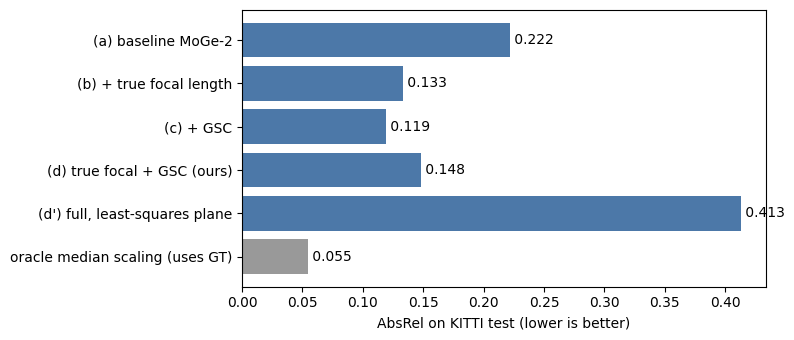

In [ ]:
# 8. Result tables + bar chart (for the report)
df = pd.read_csv(OUT)
cfg = json.load(open(f"{RES}/config.json"))
VARIANTS = [("a_baseline", "(a) baseline MoGe-2"), ("b_true_focal", "(b) + true focal length"),
            ("c_gsc", "(c) + GSC"), ("d_full", "(d) true focal + GSC (ours)"),
            ("d_lstsq", "(d') full, least-squares plane"), ("oracle", "oracle median scaling (uses GT)")]
main = pd.DataFrame([{"variant": lab,
                      "AbsRel": df[f"{k}_AbsRel"].mean(),
                      "RMSE (m)": df[f"{k}_RMSE"].mean(),
                      "delta<1.25 (%)": 100 * df[f"{k}_d1"].mean()} for k, lab in VARIANTS])
main["AbsRel change vs (a) (%)"] = 100 * (main["AbsRel"] - main["AbsRel"][0]) / main["AbsRel"][0]
main.round(4).to_csv(f"{RES}/main_table.csv", index=False)

bins = ["0_20m", "20_40m", "40_80m"]
by_dist = pd.DataFrame({"GT distance": bins,
                        "(a) AbsRel": [df[f"a_AbsRel_{b}"].mean() for b in bins],
                        "(d) AbsRel": [df[f"d_AbsRel_{b}"].mean() for b in bins]})
by_dist.round(4).to_csv(f"{RES}/by_distance.csv", index=False)

cost = pd.DataFrame([{"test images": len(df), "GPU": cfg["gpu"],
                      "MoGe-2 ms/img (auto focal)": df.ms_auto.mean(),
                      "MoGe-2 ms/img (true focal)": df.ms_true_focal.mean(),
                      "GSC ms/img": df.gsc_ms.mean(),
                      "peak GPU memory (GB)": cfg.get("peak_gpu_mem_GB"),
                      "GSC fallback (%)": 100 * df.fallback_d.mean(),
                      "mean scale s (d)": df.s_d.mean(), "mean oracle scale": df.s_oracle.mean()}])
cost.round(3).to_csv(f"{RES}/cost_table.csv", index=False)

display(main.round(4)); display(by_dist.round(4)); display(cost.round(3))
gain = -main["AbsRel change vs (a) (%)"][3]
print(f"Hypothesis (>=30% lower AbsRel, <30 ms extra): AbsRel change {gain:.1f}% lower, "
      f"GSC {df.gsc_ms.mean():.1f} ms -> {'SUPPORTED' if gain >= 30 and df.gsc_ms.mean() < 30 else 'NOT supported'}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(main["variant"][::-1], main["AbsRel"][::-1], color=["#999"] + ["#4C78A8"] * 5)
ax.set_xlabel("AbsRel on KITTI test (lower is better)")
for y, v in enumerate(main["AbsRel"][::-1]): ax.text(v, y, f" {v:.3f}", va="center")
plt.tight_layout(); plt.savefig(f"{FIG}/absrel_bar.png", dpi=200); plt.show()

In [ ]:
# 8b. GSC + sanity check (added AFTER failure analysis; range fixed a priori, not tuned on test)
LO, HI = 0.5, 2.0   # a metric model should not be off by more than 2x
rows = []
for key, s_col, fallback_key, lab in [("c_gsc", "s_c", "a_baseline", "(c) + GSC + sanity check"),
                                       ("d_full", "s_d", "b_true_focal", "(d) full + sanity check")]:
    ok = df[s_col].between(LO, HI)
    row = {"variant": lab, "rejected images": int((~ok).sum())}
    for m, name in [("AbsRel", "AbsRel"), ("RMSE", "RMSE (m)"), ("d1", "delta<1.25 (%)")]:
        vals = np.where(ok, df[f"{key}_{m}"], df[f"{fallback_key}_{m}"])
        row[name] = vals.mean() * (100 if m == "d1" else 1)
    row["AbsRel change vs (a) (%)"] = 100 * (row["AbsRel"] - df.a_baseline_AbsRel.mean()) / df.a_baseline_AbsRel.mean()
    rows.append(row)
guard = pd.DataFrame(rows); guard.round(4).to_csv(f"{RES}/sanity_check_table.csv", index=False)
display(guard.round(4))

,variant,rejected images,AbsRel,RMSE (m),delta<1.25 (%),AbsRel change vs (a) (%)
0,(c) + GSC + sanity check,8,0.0965,2.9649,92.8959,-56.5228
1,(d) full + sanity check,7,0.1220,3.9455,82.8563,-45.0313


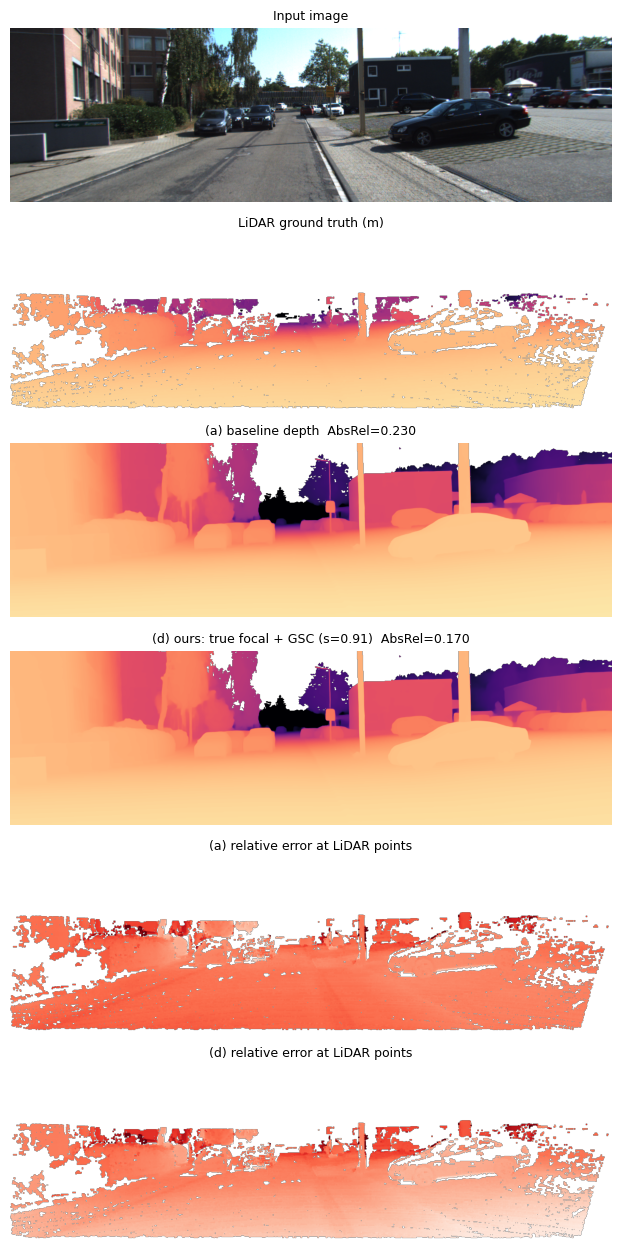

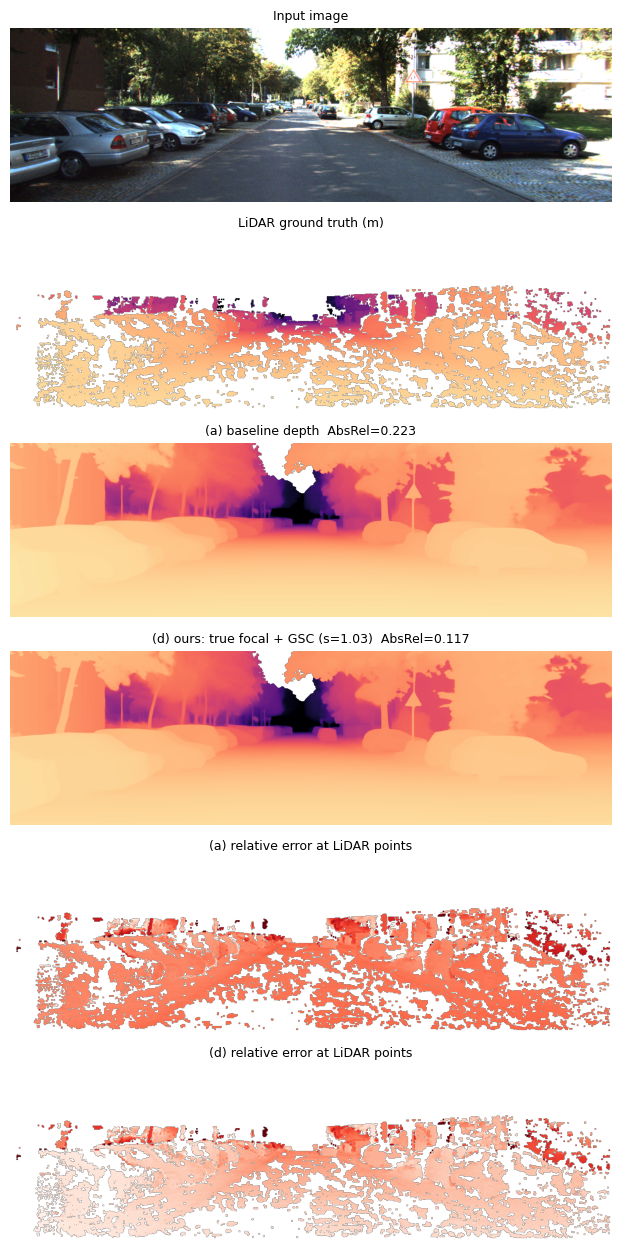

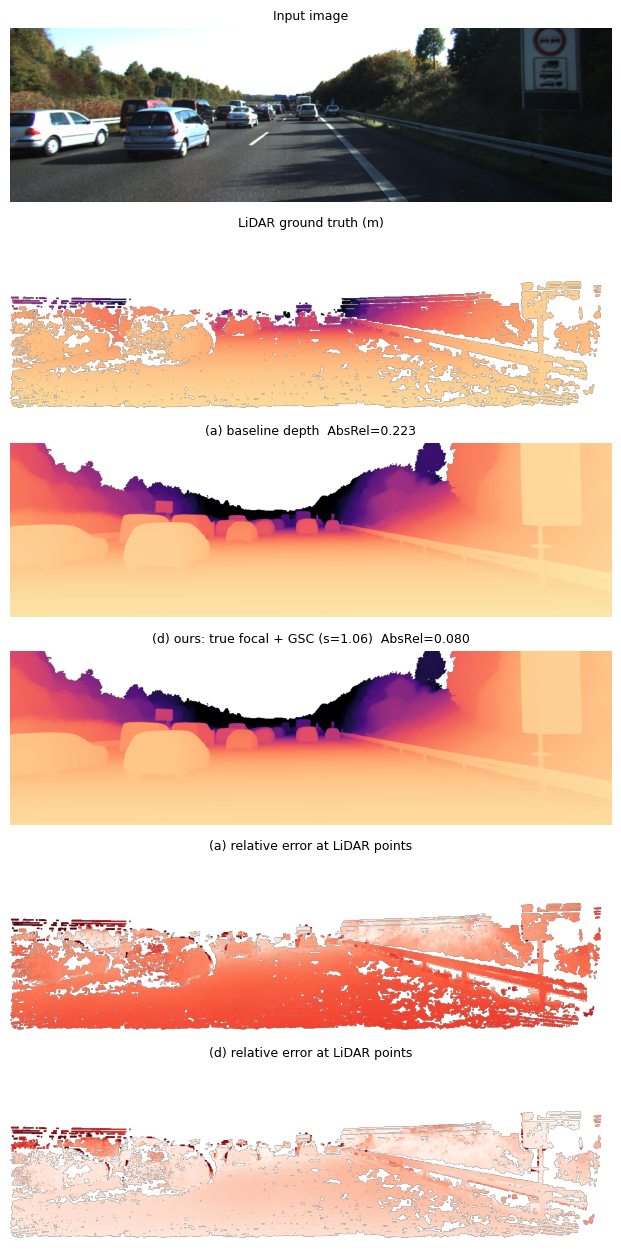

In [ ]:
# 9. Qualitative figure: image, LiDAR, baseline depth, GSC depth, error maps
def predict_all(n):
    rgb, gt, K = load_rgb(n), load_gt(n), load_K(n)
    pa, ma, _ = run_moge(rgb)
    pk, mk, _ = run_moge(rgb, fov_x=fov_x_deg(K, rgb.shape[1]))
    p_d, s, info = gsc(pk, mk, thresh=BEST_TH)
    return rgb, gt, (pa, ma), (p_d, mk), s, info

def show_example(n, save=None):
    rgb, gt, (pa, ma), (p_d, mk), s, info = predict_all(n)
    v = (gt > 0) & (gt <= MAX_DEPTH)
    da, dd = np.where(ma, pa[..., 2], np.nan), np.where(mk, p_d[..., 2], np.nan)
    ea, ed = np.full(gt.shape, np.nan), np.full(gt.shape, np.nan)
    ea[v & ma] = np.abs(da[v & ma] - gt[v & ma]) / gt[v & ma]
    ed[v & mk] = np.abs(dd[v & mk] - gt[v & mk]) / gt[v & mk]
    ker = np.ones((3, 3), np.uint8)
    thick = lambda a: np.where(cv2.dilate((~np.isnan(a) & (np.nan_to_num(a) > 0)).astype(np.uint8), ker) > 0,
                               cv2.dilate(np.nan_to_num(a).astype(np.float32), ker), np.nan)  # make sparse LiDAR points visible
    gt_show = thick(np.where(gt > 0, gt, np.nan))
    ar_a = depth_metrics(pa[..., 2], gt, v & ma)[0]; ar_d = depth_metrics(p_d[..., 2], gt, v & mk)[0]
    panels = [(rgb, "Input image", None), (gt_show, "LiDAR ground truth (m)", "magma_r"),
              (da, f"(a) baseline depth  AbsRel={ar_a:.3f}", "magma_r"),
              (dd, f"(d) ours: true focal + GSC (s={s:.2f})  AbsRel={ar_d:.3f}", "magma_r"),
              (thick(ea), "(a) relative error at LiDAR points", "Reds"), (thick(ed), "(d) relative error at LiDAR points", "Reds")]
    fig, axes = plt.subplots(len(panels), 1, figsize=(10, 2.1 * len(panels)))
    for ax, (img, title, cmap) in zip(axes, panels):
        if cmap is None: ax.imshow(img)
        elif cmap == "Reds": ax.imshow(img, cmap=cmap, vmin=0, vmax=0.5)
        else: ax.imshow(img, cmap=cmap, vmin=0, vmax=MAX_DEPTH)
        ax.set_title(title, fontsize=9); ax.axis("off")
    plt.tight_layout()
    if save: plt.savefig(save, dpi=150)
    plt.show()
    return ar_a, ar_d, s, info

df["gain"] = df["a_baseline_AbsRel"] - df["d_full_AbsRel"]
examples = df.sort_values("gain").iloc[[len(df) // 4, len(df) // 2, 3 * len(df) // 4]]["name"]
for k, n in enumerate(examples):
    show_example(n, save=f"{FIG}/qualitative_{k}.png")

,name,a_baseline_AbsRel,d_full_AbsRel,s_d,s_oracle,h_pred_d,inliers_d,fallback_d
258,2011_09_26_drive_0036_sync_image_0000000215_im...,0.206,6.151,15.170,1.264,0.109,11260,False
225,2011_09_26_drive_0036_sync_image_0000000116_im...,0.146,5.784,15.332,1.110,0.108,10773,False
427,2011_09_26_drive_0095_sync_image_0000000035_im...,0.135,4.263,7.294,1.155,0.226,10829,False
269,2011_09_26_drive_0036_sync_image_0000000248_im...,0.192,2.349,4.046,1.260,0.408,10980,False
267,2011_09_26_drive_0036_sync_image_0000000242_im...,0.179,2.294,4.009,1.239,0.412,10899,False


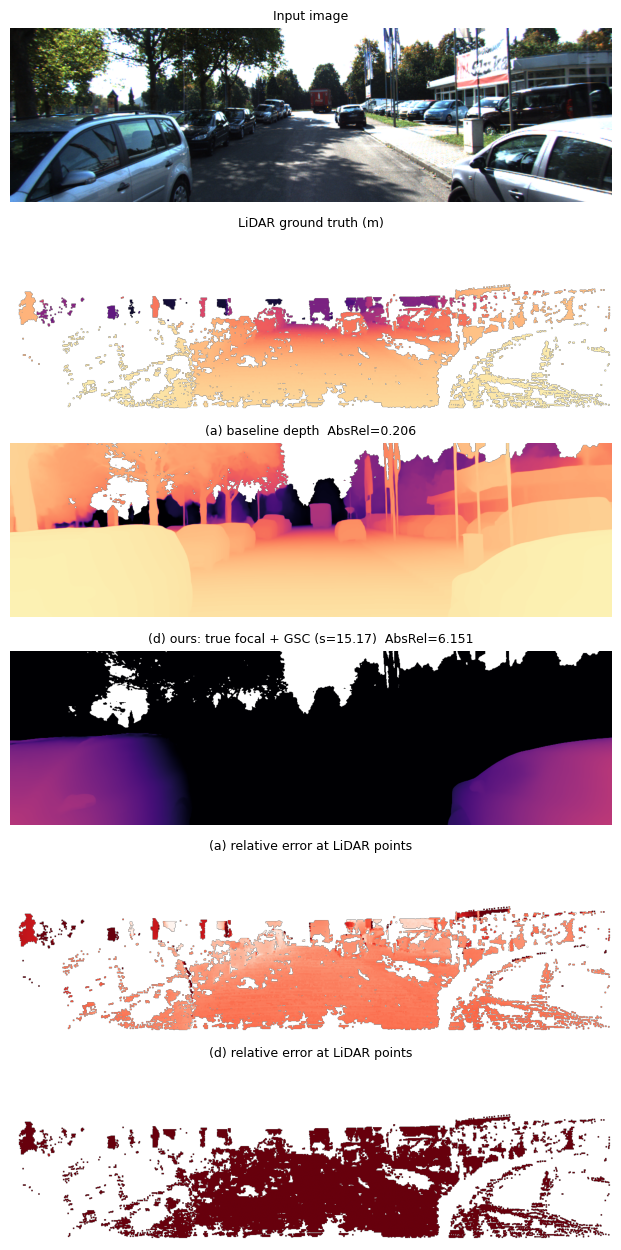

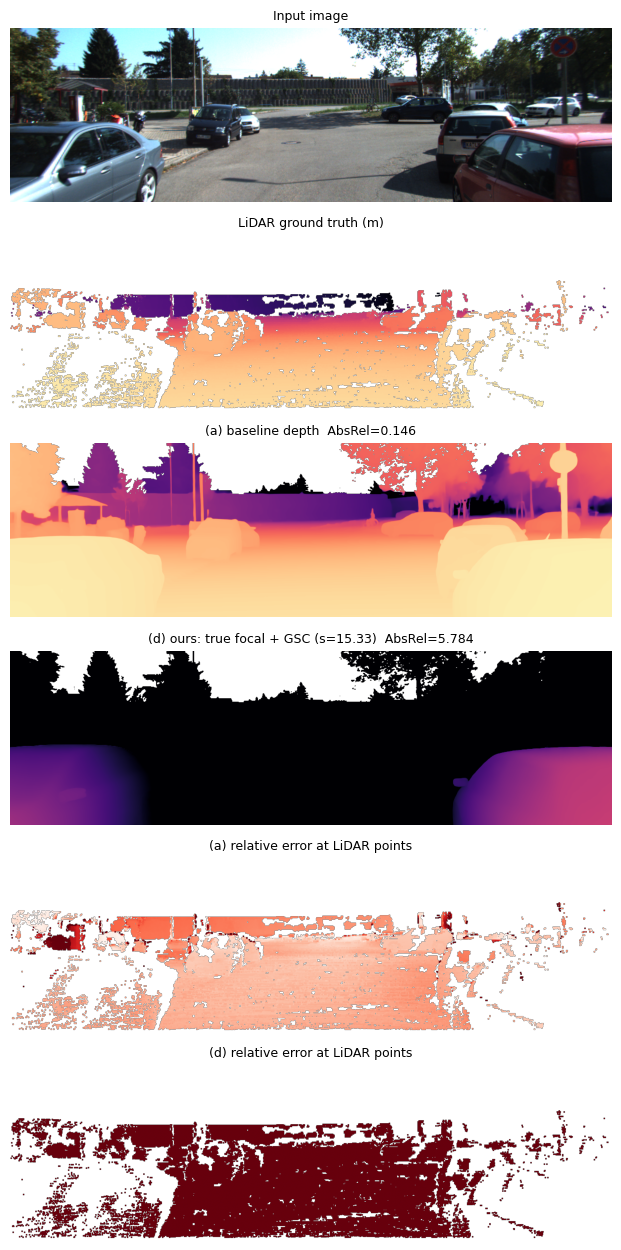

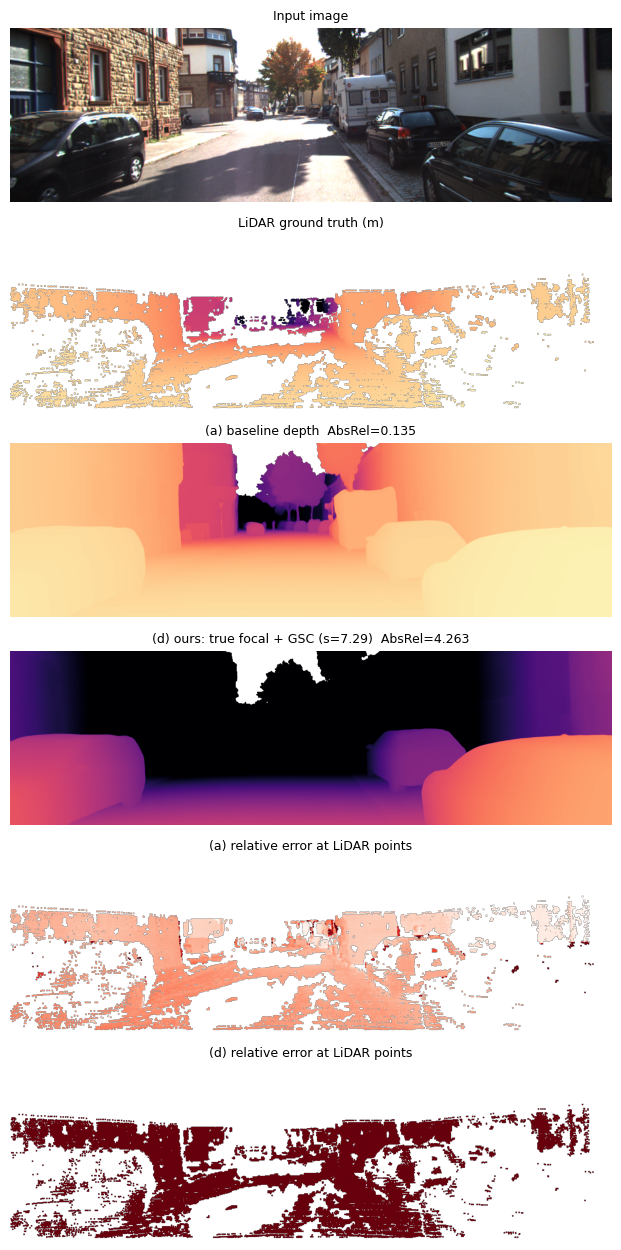

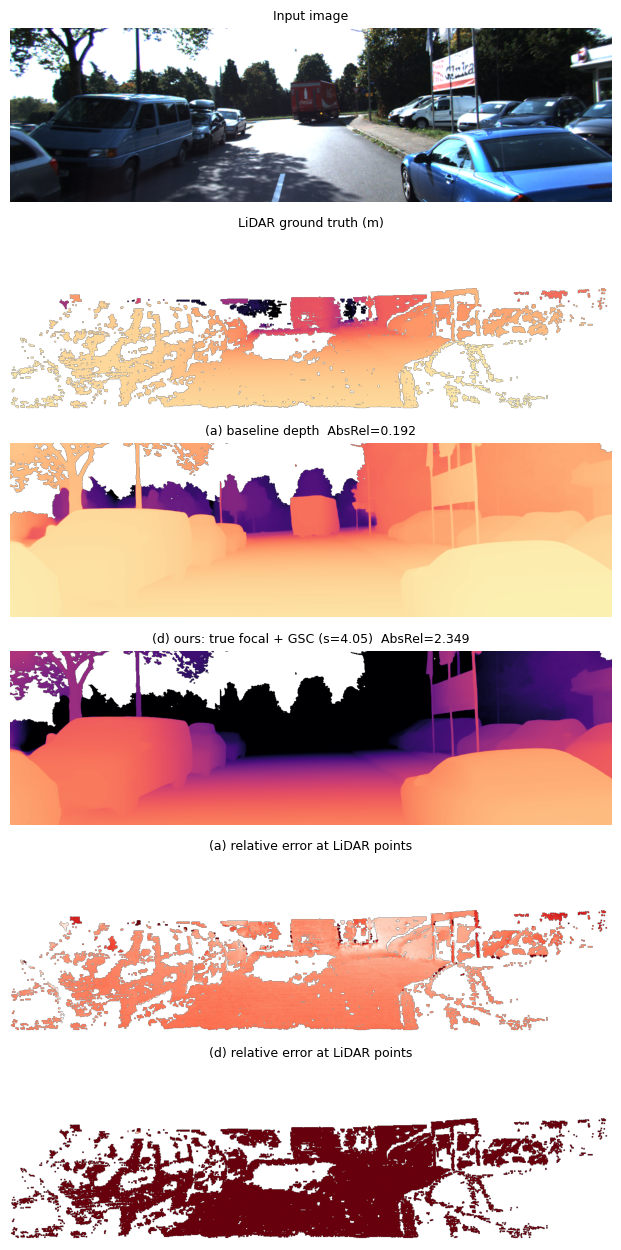

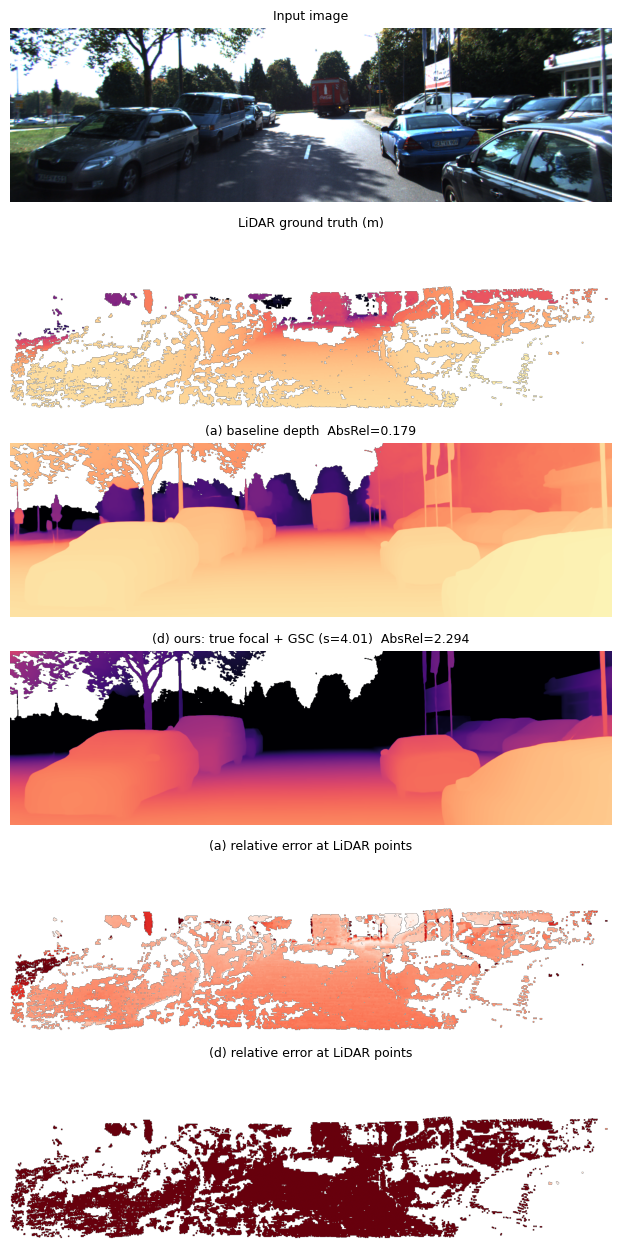

In [ ]:
# 10. Failure analysis: where GSC made things worse or could not find the road
worst = df.sort_values("gain").head(5)
fails = pd.concat([worst, df[df.fallback_d]]).drop_duplicates("name").head(6)
display(fails[["name", "a_baseline_AbsRel", "d_full_AbsRel", "s_d", "s_oracle", "h_pred_d",
               "inliers_d", "fallback_d"]].round(3))
fails.to_csv(f"{RES}/failure_cases.csv", index=False)
for k, n in enumerate(fails["name"]):
    show_example(n, save=f"{FIG}/failure_{k}.png")
# Write one line per case in the report: e.g. road slopes up/down, cars cover the road, bridge/shadow edge,
# s far from the oracle scale -> the fitted plane was not the road.

Typical 2011_09_26_drive_0079_sync_image_0000000050_image_02 AbsRel a=0.213 c=0.086 s=1.17
Failure 2011_09_26_drive_0095_sync_image_0000000035_image_03 AbsRel a=0.135 c=5.593 s=13.81


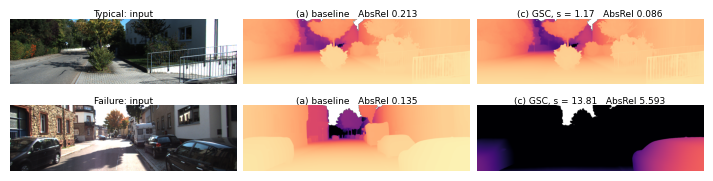

Saved /content/drive/MyDrive/GulfMetric/results/figures/qualitative.png  -> upload it to Overleaf as figures/qualitative.png


In [ ]:
# ---------- Cell 12: compact qualitative figure for the report (Figure 3) ----------
# 12. Compact qualitative figure for the report: one typical case + one parked-car failure
df = pd.read_csv(OUT)
df["gain_c"] = df.a_baseline_AbsRel - df.c_gsc_AbsRel
typical = df.iloc[(df.gain_c - df.gain_c.median()).abs().argsort()]["name"].iloc[0]   # median improvement
failure = df.sort_values("c_gsc_AbsRel", ascending=False)["name"].iloc[0]           # worst case for (c)
fig, axes = plt.subplots(2, 3, figsize=(7.0, 1.75))
for row, (label, n) in enumerate([("Typical", typical), ("Failure", failure)]):
    rgb, gt, K = load_rgb(n), load_gt(n), load_K(n)
    pa, ma, _ = run_moge(rgb)
    pc, s, info = gsc(pa, ma, thresh=BEST_TH)
    v = (gt > 0) & (gt <= MAX_DEPTH) & ma
    ar_a = depth_metrics(pa[..., 2], gt, v)[0]; ar_c = depth_metrics(pc[..., 2], gt, v)[0]
    panels = [(rgb, f"{label}: input"),
              (np.where(ma, pa[..., 2], np.nan), f"(a) baseline   AbsRel {ar_a:.3f}"),
              (np.where(ma, pc[..., 2], np.nan), f"(c) GSC, s = {s:.2f}   AbsRel {ar_c:.3f}")]
    for col, (img, title) in enumerate(panels):
        ax = axes[row, col]
        if col == 0: ax.imshow(img)
        else: ax.imshow(img, cmap="magma_r", vmin=0, vmax=MAX_DEPTH)
        ax.set_title(title, fontsize=6.5, pad=2); ax.axis("off")
    print(label, n, f"AbsRel a={ar_a:.3f} c={ar_c:.3f} s={s:.2f}")
plt.subplots_adjust(left=0.005, right=0.995, top=0.9, bottom=0.01, wspace=0.03, hspace=0.25)
plt.savefig(f"{FIG}/qualitative.png", dpi=300, bbox_inches="tight", pad_inches=0.02)
plt.show()
print("Saved", f"{FIG}/qualitative.png  -> upload it to Overleaf as figures/qualitative.png")


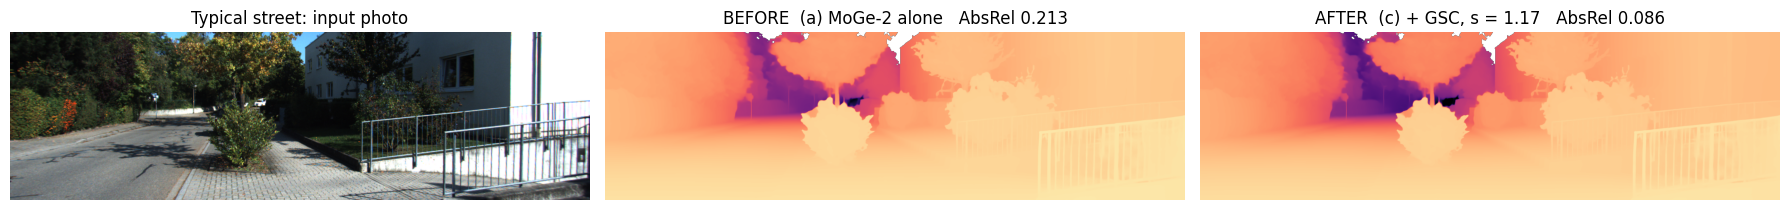

Typical street  (2011_09_26_drive_0079_sync_image_0000000050_image_02)
  camera height in MoGe-2's world: 1.41 m  ->  s = 1.65 / 1.41 = 1.17
  error AbsRel: 0.213 -> 0.086   |   MoGe-2 446 ms, GSC 44 ms
  plausibility check (0.5 <= s <= 2): ACCEPT



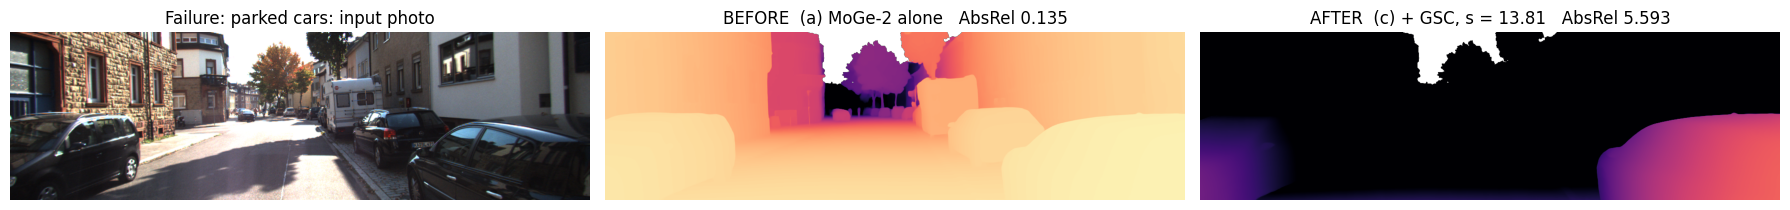

Failure: parked cars  (2011_09_26_drive_0095_sync_image_0000000035_image_03)
  camera height in MoGe-2's world: 0.12 m  ->  s = 1.65 / 0.12 = 13.81
  error AbsRel: 0.135 -> 5.593   |   MoGe-2 343 ms, GSC 24 ms
  plausibility check (0.5 <= s <= 2): REJECT -> keep the original MoGe-2 answer



In [7]:
# 13. LIVE DEMO (use this one in the presentation): baseline (a) vs. ours (c) on held-out TEST images
# Run cells 1-5 first (setup + model, about 5 min). Then run only this cell.
import random
BEST_TH = json.load(open(f"{RES}/config.json"))["ransac_thresh_m"]      # 0.2 m, chosen on dev

def demo(n, title):
    rgb, gt, K = load_rgb(n), load_gt(n), load_K(n)
    pa, ma, ms_model = run_moge(rgb)                  # (a) baseline: frozen MoGe-2
    pc, s, info = gsc(pa, ma, thresh=BEST_TH)         # (c) ours: GSC on top
    ok = 0.5 <= s <= 2.0                              # plausibility check (post hoc)
    v = (gt > 0) & (gt <= MAX_DEPTH) & ma
    ar_a = depth_metrics(pa[..., 2], gt, v)[0]
    ar_c = depth_metrics(pc[..., 2], gt, v)[0]

    fig, ax = plt.subplots(1, 3, figsize=(18, 3.3))
    ax[0].imshow(rgb);                                                    ax[0].set_title(f"{title}: input photo")
    ax[1].imshow(np.where(ma, pa[..., 2], np.nan), cmap="magma_r", vmin=0, vmax=MAX_DEPTH)
    ax[1].set_title(f"BEFORE  (a) MoGe-2 alone   AbsRel {ar_a:.3f}")
    ax[2].imshow(np.where(ma, pc[..., 2], np.nan), cmap="magma_r", vmin=0, vmax=MAX_DEPTH)
    ax[2].set_title(f"AFTER  (c) + GSC, s = {s:.2f}   AbsRel {ar_c:.3f}")
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()

    print(f"{title}  ({n})")
    print(f"  camera height in MoGe-2's world: {info['h_pred']:.2f} m  ->  s = 1.65 / {info['h_pred']:.2f} = {s:.2f}")
    print(f"  error AbsRel: {ar_a:.3f} -> {ar_c:.3f}   |   MoGe-2 {ms_model:.0f} ms, GSC {info['gsc_ms']:.0f} ms")
    print(f"  plausibility check (0.5 <= s <= 2): {'ACCEPT' if ok else 'REJECT -> keep the original MoGe-2 answer'}\n")

demo("2011_09_26_drive_0079_sync_image_0000000050_image_02", "Typical street")
demo("2011_09_26_drive_0095_sync_image_0000000035_image_03", "Failure: parked cars")

# Optional, if the professor asks for another image: a random held-out test image
# demo(random.choice(test_names), "Random test image")